In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
# 读取整个Excel文件
df_SHF = pd.read_csv('..\data\SHF.csv') #地表热流数据
df_ECM = pd.read_excel('..\data\ECM.xls') #地质数据集
df_EMAG = pd.read_excel('..\data\EMAG.xls') #地表磁数据集
df_DEM = pd.read_excel('..\data\DEM.xls') #地形数据集
df_CTC = pd.read_excel('..\data\CrustalThiChina.xlsx') #中国沉积层厚度/地震波波速比数据集
df_GRD = pd.read_excel('..\data\gravityAnomaly.xlsx') 
df_CPD = pd.read_csv('..\data\cpd.csv') #Curie Point Depth数据集
df_RID = pd.read_csv('..\data\\ridge_clip.csv') #洋中脊距离数据集
df_LAB = pd.read_csv('..\data\LAB_extracted.csv') #LAB数据集

In [3]:
print("SHF列名:", df_SHF.columns.tolist())
print("ECM列名:", df_ECM.columns.tolist())
print("EMAG列名:", df_EMAG.columns.tolist())
print("DEM列名:", df_DEM.columns.tolist())
print("CTC列名:", df_CTC.columns.tolist())
print("GRD列名:", df_GRD.columns.tolist())
print("CPD列名:", df_CPD.columns.tolist())
print("RID列名:", df_RID.columns.tolist())
print("LAB列名:", df_LAB.columns.tolist())

SHF列名: ['数据编号', 'Lon', 'Lat', 'SHF__mW_m2_']
ECM列名: ['OBJECTID', 'Numb', 'Lon', 'Lat', 'Hcc', 'Sed', 'Hc', 'Type', 'DLy1', 'DLy2', 'DLy3', 'TLy1', 'TLy2', 'TLy3', 'VP1', 'VP2', 'VP3', 'VS1', 'VS2', 'VS3', 'VPN', 'VSN', 'RHO1', 'RHO2', 'RHO3', 'RHON']
EMAG列名: ['OBJECTID', 'pointid', 'Magnetic_Anomaly_Value(nT)', 'Lon', 'Lat']
DEM列名: ['OBJECTID', 'pointid', 'DEM', 'Lon', 'Lat']
CTC列名: ['Lon', 'Lat', 'H(km)', '△H(km)', 'κ', '△κ', 'RF type']
GRD列名: ['pointid', 'Lon', 'Lat', 'RASTERVALU']
CPD列名: ['Lon', 'Lat', 'cpd']
RID列名: ['Lon', 'Lat', 'Ridge']
LAB列名: ['Lon', 'Lat', 'LAB']


In [4]:
# 如果知道数据是网格数据，可以这样分析
def analyze_grid_resolution(df, lat_col='Latitude', lon_col='Longitude'):
    """专门分析网格数据的分辨率"""
    # 提取唯一经纬度值并排序
    latitudes = sorted(df[lat_col].unique())
    longitudes = sorted(df[lon_col].unique())
    
    print(f"纬度点数量: {len(latitudes)}")
    print(f"经度点数量: {len(longitudes)}")
    
    if len(latitudes) > 1:
        lat_spacing_min = latitudes[1] - latitudes[0]
        lat_spacing_max = latitudes[1] - latitudes[0]
        for i in range(1, len(latitudes)):
            lat_spacing_min = min(latitudes[i] - latitudes[i-1] ,lat_spacing_min)
            lat_spacing_max = max(latitudes[i] - latitudes[i-1], lat_spacing_max)
    if abs(lat_spacing_min - lat_spacing_max) > 0.001:
        print(f"纬度间距: {lat_spacing_min:.4f}° - {lat_spacing_max:.4f}°")
    else:
        print(f"纬度间距: {lat_spacing_min:.4f}°")

    
    if len(longitudes) > 1:
        lon_spacing_min = longitudes[1] - longitudes[0]
        lon_spacing_max = longitudes[1] - longitudes[0]
        for i in range(1, len(longitudes)):
            lon_spacing_min = min(longitudes[i] - longitudes[i-1] ,lon_spacing_min)
            lon_spacing_max = max(longitudes[i] - longitudes[i-1], lon_spacing_max)
    if abs(lon_spacing_min - lon_spacing_max) > 0.001:
        print(f"纬度间距: {lon_spacing_min:.4f}° - {lon_spacing_max:.4f}°")
    else:
        print(f"纬度间距: {lon_spacing_min:.4f}°")
    
    # 判断网格类型
    if len(latitudes) * len(longitudes) == len(df):
        print("网格类型: 规则矩形网格")
        print(f"网格大小: {len(latitudes)} × {len(longitudes)}")
    else:
        print("网格类型: 不规则网格或散点")

# 对每个数据集应用（需要知道实际的经纬度列名）
analyze_grid_resolution(df_ECM, 'Lat', 'Lon')
analyze_grid_resolution(df_EMAG, 'Lat', 'Lon')
analyze_grid_resolution(df_DEM, 'Lat', 'Lon')
analyze_grid_resolution(df_CTC, 'Lat', 'Lon')
analyze_grid_resolution(df_GRD, 'Lat', 'Lon')
analyze_grid_resolution(df_CPD, 'Lat', 'Lon')
analyze_grid_resolution(df_RID, 'Lat', 'Lon')
analyze_grid_resolution(df_LAB, 'Lat', 'Lon')

纬度点数量: 16
经度点数量: 11
纬度间距: 1.0000°
纬度间距: 1.0000°
网格类型: 不规则网格或散点
纬度点数量: 168
经度点数量: 113
纬度间距: 0.1000°
纬度间距: 0.1000°
网格类型: 不规则网格或散点
纬度点数量: 84
经度点数量: 56
纬度间距: 0.2000°
纬度间距: 0.2000°
网格类型: 不规则网格或散点
纬度点数量: 156
经度点数量: 204
纬度间距: 0.1250° - 1.0000°
纬度间距: 0.1250° - 3.5000°
网格类型: 不规则网格或散点
纬度点数量: 168
经度点数量: 113
纬度间距: 0.1000°
纬度间距: 0.1000°
网格类型: 不规则网格或散点
纬度点数量: 80
经度点数量: 128
纬度间距: 0.5000°
纬度间距: 0.5000°
网格类型: 规则矩形网格
网格大小: 80 × 128
纬度点数量: 32
经度点数量: 335
纬度间距: 0.5000°
纬度间距: 0.0008° - 0.4021°
网格类型: 不规则网格或散点
纬度点数量: 90
经度点数量: 180
纬度间距: 2.0000°
纬度间距: 2.0000°
网格类型: 规则矩形网格
网格大小: 90 × 180


In [5]:
import numpy as np
from scipy.interpolate import griddata
import warnings
warnings.filterwarnings('ignore')


In [6]:
# 计算平均波速
# 分母：总厚度
total_thickness = df_ECM['TLy1'] + df_ECM['TLy2'] + df_ECM['TLy3']

# 计算 VPA 和 VSA（避免除零，可用 .where 或直接计算，假设厚度和不为零）
df_ECM['VPA'] = (df_ECM['VP1'] * df_ECM['TLy1'] + df_ECM['VP2'] * df_ECM['TLy2'] + df_ECM['VP3'] * df_ECM['TLy3']) / total_thickness
df_ECM['VSA'] = (df_ECM['VS1'] * df_ECM['TLy1'] + df_ECM['VS2'] * df_ECM['TLy2'] + df_ECM['VS3'] * df_ECM['TLy3']) / total_thickness
df_ECM['RHOA'] = (df_ECM['RHO1'] * df_ECM['TLy1'] + df_ECM['RHO2'] * df_ECM['TLy2'] + df_ECM['RHO3'] * df_ECM['TLy3']) / total_thickness
# 删除原有的 VPn、VSn 和 TLn 列
cols_to_drop = ['VP1', 'VP2', 'VP3', 'VS1', 'VS2', 'VS3', 'TLy1', 'TLy2', 'TLy3', 'DLy1', 'DLy2', 'DLy3', 'RHO1', 'RHO2', 'RHO3']
df_ECM = df_ECM.drop(columns=cols_to_drop, errors='ignore')  # errors='ignore' 避免列不存在时报错

# 查看结果
print(df_ECM.head())

# 保存结果到 Excel 文件
df_ECM.to_excel('..\data\ECM_process.xlsx', index=False)


   OBJECTID   Numb    Lon   Lat      Hcc   Sed       Hc  Type       VPN  \
0         1  24055  114.5  23.5  30.2638  0.01  30.2738  EXCT  8.009771   
1         2  24057  116.5  23.5  29.4544  0.10  29.5544  EXCT  8.009771   
2         3  24058  117.5  23.5  28.0229  0.50  28.5229  COMA  8.023201   
3         4  24059  118.5  23.5  28.3314  0.80  29.1314  COMA  8.023201   
4         5  23694  113.5  24.5  31.4324  0.01  31.4424  EXCT  8.009771   

        VSN      RHON       VPA       VSA      RHOA  
0  4.371981  3.294482  6.388962  3.632915  2.808968  
1  4.371981  3.294482  6.388962  3.632915  2.808968  
2  4.485504  3.299267  6.366742  3.640961  2.803272  
3  4.485504  3.299267  6.366743  3.640962  2.803272  
4  4.371981  3.294482  6.388962  3.632915  2.808968  


In [7]:
def get_target_range(data, resolution=0.1, lat_col='Lat', lon_col='Lon'):
    """获取目标网格范围和网格点"""
    
    # 获取范围并扩展到0.1度的整数倍
    lat_min, lat_max = data[lat_col].min(), data[lat_col].max()
    lon_min, lon_max = data[lon_col].min(), data[lon_col].max()
    
    lat_min = np.floor(lat_min / resolution) * resolution
    lat_max = np.ceil(lat_max / resolution) * resolution
    lon_min = np.floor(lon_min / resolution) * resolution
    lon_max = np.ceil(lon_max / resolution) * resolution
    
    # 生成网格点
    lats = np.arange(lat_min, lat_max + resolution/2, resolution)
    lons = np.arange(lon_min, lon_max + resolution/2, resolution)
    
    print(f"目标范围: 纬度 [{lat_min:.2f}, {lat_max:.2f}]，经度 [{lon_min:.2f}, {lon_max:.2f}]")
    print(f"网格大小: {len(lats)}×{len(lons)} = {len(lats)*len(lons)}个点")
    
    return lats, lons

get_target_range(df_EMAG)

目标范围: 纬度 [22.60, 39.40]，经度 [112.60, 123.90]
网格大小: 169×114 = 19266个点


(array([22.6, 22.7, 22.8, 22.9, 23. , 23.1, 23.2, 23.3, 23.4, 23.5, 23.6,
        23.7, 23.8, 23.9, 24. , 24.1, 24.2, 24.3, 24.4, 24.5, 24.6, 24.7,
        24.8, 24.9, 25. , 25.1, 25.2, 25.3, 25.4, 25.5, 25.6, 25.7, 25.8,
        25.9, 26. , 26.1, 26.2, 26.3, 26.4, 26.5, 26.6, 26.7, 26.8, 26.9,
        27. , 27.1, 27.2, 27.3, 27.4, 27.5, 27.6, 27.7, 27.8, 27.9, 28. ,
        28.1, 28.2, 28.3, 28.4, 28.5, 28.6, 28.7, 28.8, 28.9, 29. , 29.1,
        29.2, 29.3, 29.4, 29.5, 29.6, 29.7, 29.8, 29.9, 30. , 30.1, 30.2,
        30.3, 30.4, 30.5, 30.6, 30.7, 30.8, 30.9, 31. , 31.1, 31.2, 31.3,
        31.4, 31.5, 31.6, 31.7, 31.8, 31.9, 32. , 32.1, 32.2, 32.3, 32.4,
        32.5, 32.6, 32.7, 32.8, 32.9, 33. , 33.1, 33.2, 33.3, 33.4, 33.5,
        33.6, 33.7, 33.8, 33.9, 34. , 34.1, 34.2, 34.3, 34.4, 34.5, 34.6,
        34.7, 34.8, 34.9, 35. , 35.1, 35.2, 35.3, 35.4, 35.5, 35.6, 35.7,
        35.8, 35.9, 36. , 36.1, 36.2, 36.3, 36.4, 36.5, 36.6, 36.7, 36.8,
        36.9, 37. , 37.1, 37.2, 37.3, 

In [8]:
def kriging_interpolate(df, lat_col, lon_col, data_col, 
                       target_lats, target_lons,
                       variogram_model='linear', nlags=10):
    """执行空间插值（使用griddata线性方法）"""
    # 提取有效数据
    mask = df[data_col].notna()
    if mask.sum() < 4:  # 至少需要4个点
        return np.full((len(target_lats), len(target_lons)), np.nan)
    
    x = df.loc[mask, lon_col].values
    y = df.loc[mask, lat_col].values
    z = df.loc[mask, data_col].values
    
    try:
        # 创建网格点坐标
        grid_x, grid_y = np.meshgrid(target_lons, target_lats)
        
        # 构造输入点坐标
        points = np.column_stack([x, y])
        xi = np.column_stack([grid_x.flatten(), grid_y.flatten()])
        
        # 使用linear方法进行插值
        z_grid = griddata(points, z, xi, method='linear', fill_value=np.nan)
        
        # 对于NaN点，使用nearest方法填充
        nan_mask = np.isnan(z_grid)
        if nan_mask.sum() > 0:
            z_nearest = griddata(points, z, xi[nan_mask], method='nearest')
            z_grid[nan_mask] = z_nearest
        
        z_grid = z_grid.reshape(grid_x.shape)
        
        return z_grid
    
    except Exception as e:
        print(f"  插值失败: {e}")
        return np.full((len(target_lats), len(target_lons)), np.nan)


In [9]:
def merge_all_datasets(datasets, target_lats, target_lons, lat_col='Lat', lon_col='Lon'):
    """将所有数据集重采样并合并到统一网格"""
    
    # 创建基础网格
    grid_lon, grid_lat = np.meshgrid(target_lons, target_lats)
    n_points = len(target_lats) * len(target_lons)
    
    # 初始化结果DataFrame
    result_df = pd.DataFrame({
        'Latitude': grid_lat.flatten(),
        'Longitude': grid_lon.flatten()
    })
    
    # 对每个数据集进行处理
    for name, df in datasets.items():
        print(f"\n处理 {name}...")
        
        data_cols = [col for col in df.columns if col not in [lat_col, lon_col]]
        
        for col_idx, data_col in enumerate(data_cols):
            print(f"  列 {col_idx+1}/{len(data_cols)}: {data_col}", end="")
            if data_col == 'OBJECTID':  # 跳过OBJECTID列
                print(f" - 跳过")
                continue
            if data_col == 'pointid':  # 跳过pointid列
                print(f" - 跳过")
                continue
            if data_col == 'Numb':  # 跳过Numb列
                print(f" - 跳过")
                continue
            if data_col == 'Type':  # 跳过Type列
                print(f" - 跳过")
                continue
            if data_col == 'RF type':  # 跳过RF type列
                print(f" - 跳过")
                continue
            if data_col == 'Hcc':  # 跳过Hcc列
                print(f" - 跳过")
                continue
            if data_col == 'VPN' or data_col == 'VPA' or data_col == 'VSA' or data_col == 'VSN':  # 跳过VPN, VPA, VSA, VSN列
                print(f" - 跳过")
                continue
            if data_col == 'RHON':  # 跳过RHON列
                print(f" - 跳过")
                continue
            if data_col == '△H(km)' or data_col == '△κ':  # 跳过△H(km)和△κ列
                print(f" - 跳过")
                continue

            # 插值
            z_grid = kriging_interpolate(
                df, lat_col, lon_col, data_col,
                target_lats, target_lons
            )
            
            # 添加到结果DataFrame
            result_df[f"{name}_{data_col}"] = z_grid.flatten()
            
            # 计算有效数据比例
            valid_ratio = 1 - result_df[f"{name}_{data_col}"].isna().sum() / n_points
            print(f" - 有效数据: {valid_ratio:.1%}")
    
    return result_df

In [10]:
datasets = {}
datasets['ECM'] = pd.read_excel('..\data\ECM_process.xlsx')
datasets['EMAG'] = pd.read_excel('..\data\EMAG.xls')
datasets['DEM'] = pd.read_excel('..\data\DEM.xls')
datasets['CTC'] = pd.read_excel('..\data\CrustalThiChina.xlsx')
datasets['GRD'] = pd.read_excel('..\data\gravityAnomaly.xlsx')
datasets['CSRM'] = pd.read_csv('..\data\CSRM1_processed.csv')
datasets['CPD'] = pd.read_csv('..\data\cpd.csv')
datasets['RID'] = pd.read_csv('..\data\\ridge_clip.csv')
datasets['LAB'] = pd.read_csv('..\data\LAB_extracted.csv')

In [11]:
target_lats, target_lons = get_target_range(df_EMAG, resolution=0.2)
print("\n开始重采样和合并...")

merged_df = merge_all_datasets(datasets, target_lats, target_lons)

目标范围: 纬度 [22.60, 39.40]，经度 [112.60, 124.00]
网格大小: 85×58 = 4930个点

开始重采样和合并...

处理 ECM...
  列 1/12: OBJECTID - 跳过
  列 2/12: Numb - 跳过
  列 3/12: Hcc - 跳过
  列 4/12: Sed - 有效数据: 100.0%
  列 5/12: Hc - 有效数据: 100.0%
  列 6/12: Type - 跳过
  列 7/12: VPN - 跳过
  列 8/12: VSN - 跳过
  列 9/12: RHON - 跳过
  列 10/12: VPA - 跳过
  列 11/12: VSA - 跳过
  列 12/12: RHOA - 有效数据: 100.0%

处理 EMAG...
  列 1/3: OBJECTID - 跳过
  列 2/3: pointid - 跳过
  列 3/3: Magnetic_Anomaly_Value(nT) - 有效数据: 100.0%

处理 DEM...
  列 1/3: OBJECTID - 跳过
  列 2/3: pointid - 跳过
  列 3/3: DEM - 有效数据: 100.0%

处理 CTC...
  列 1/5: H(km) - 有效数据: 100.0%
  列 2/5: △H(km) - 跳过
  列 3/5: κ - 有效数据: 100.0%
  列 4/5: △κ - 跳过
  列 5/5: RF type - 跳过

处理 GRD...
  列 1/2: pointid - 跳过
  列 2/2: RASTERVALU - 有效数据: 100.0%

处理 CSRM...
  列 1/2: vp - 有效数据: 100.0%
  列 2/2: vs - 有效数据: 100.0%

处理 CPD...
  列 1/1: cpd - 有效数据: 100.0%

处理 RID...
  列 1/1: Ridge - 有效数据: 100.0%

处理 LAB...
  列 1/1: LAB - 有效数据: 100.0%


In [12]:
print(f"\n合并后数据形状: {merged_df.shape}")
print(f"合并后列数: {len(merged_df.columns)}")


合并后数据形状: (4930, 15)
合并后列数: 15



开始生成可视化图表...
加载 shapefile 失败: Invalid projection: EPSG:4326: (Internal Proj Error: proj_create: no database context specified)，将不绘制轮廓线
正在为数据集 ECM 的 3 个列生成连续图...


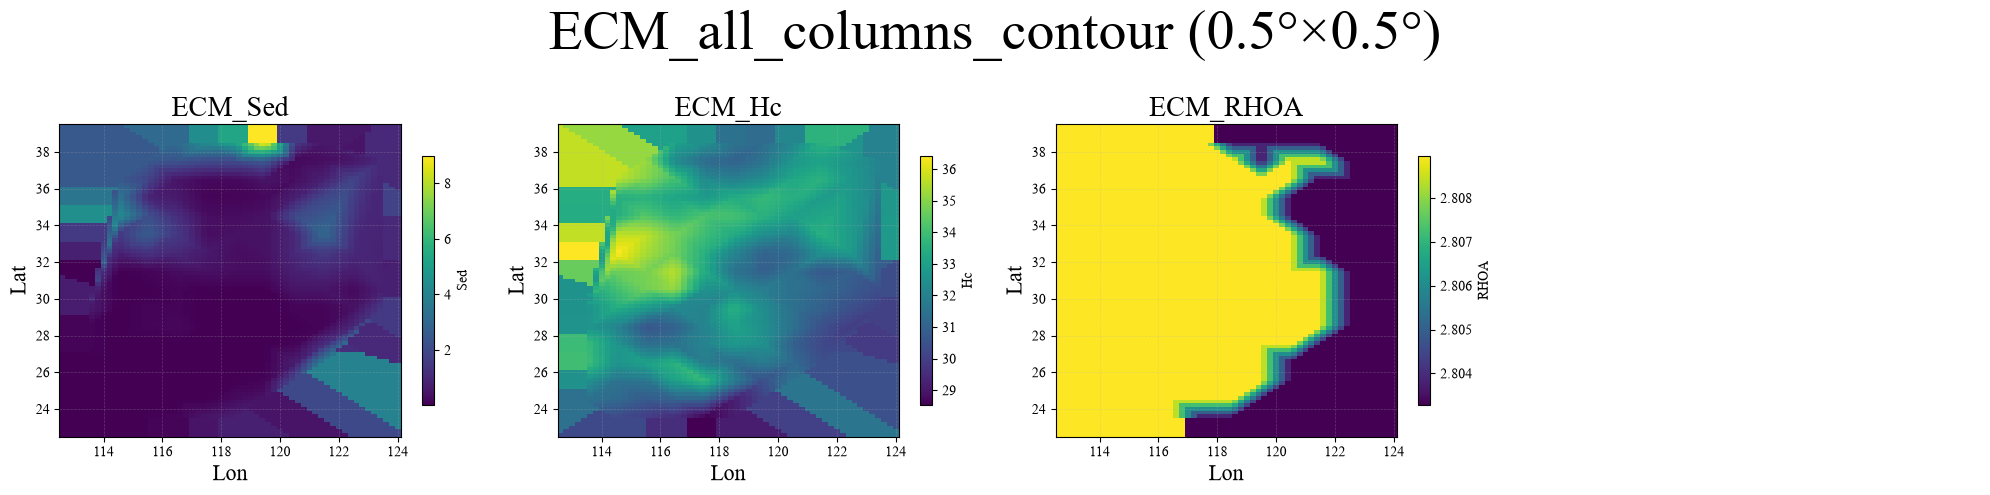

正在为数据集 EMAG 的 1 个列生成连续图...


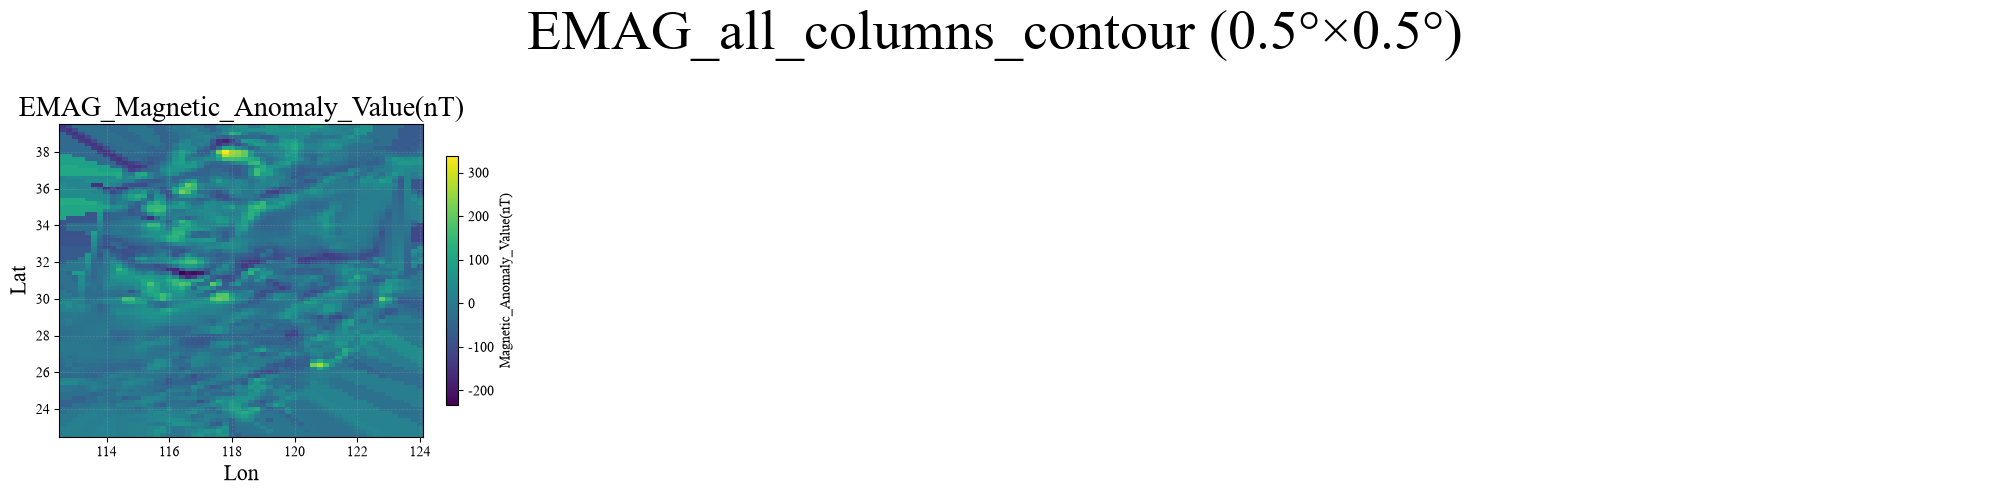

正在为数据集 DEM 的 1 个列生成连续图...


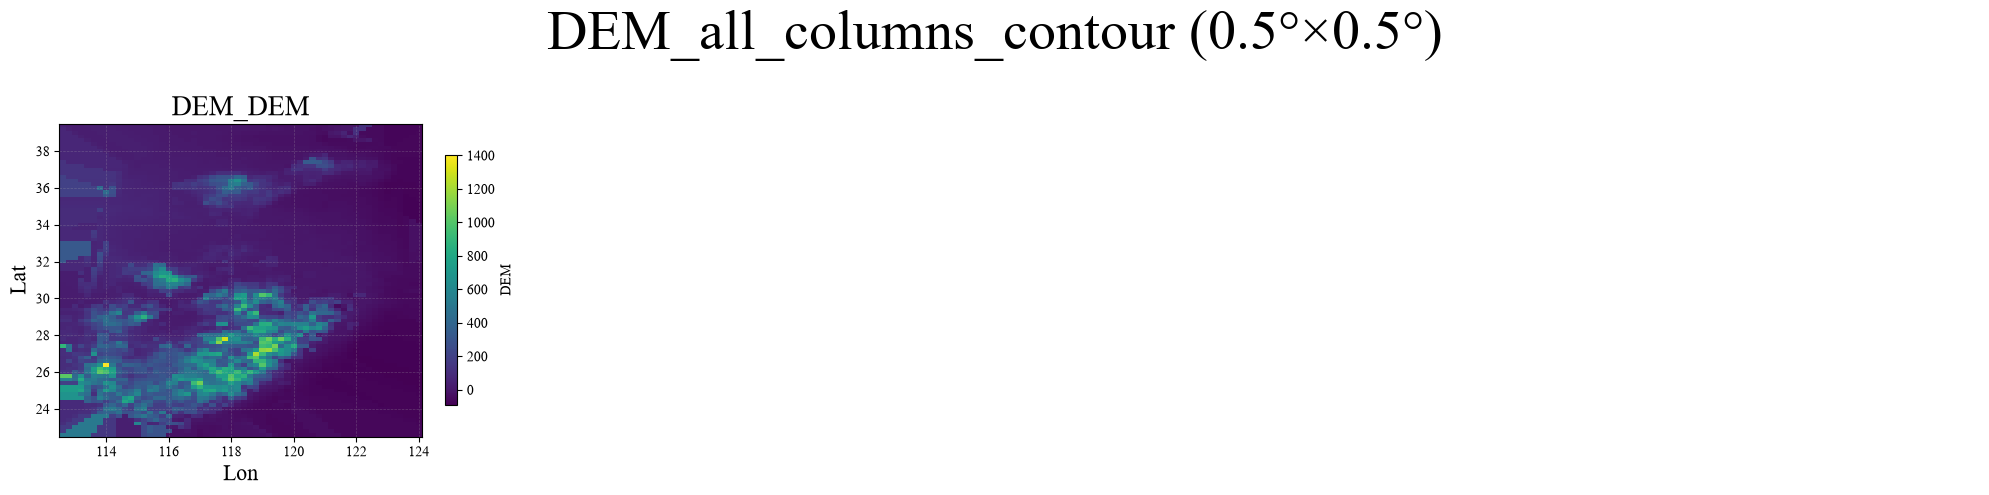

正在为数据集 CTC 的 2 个列生成连续图...


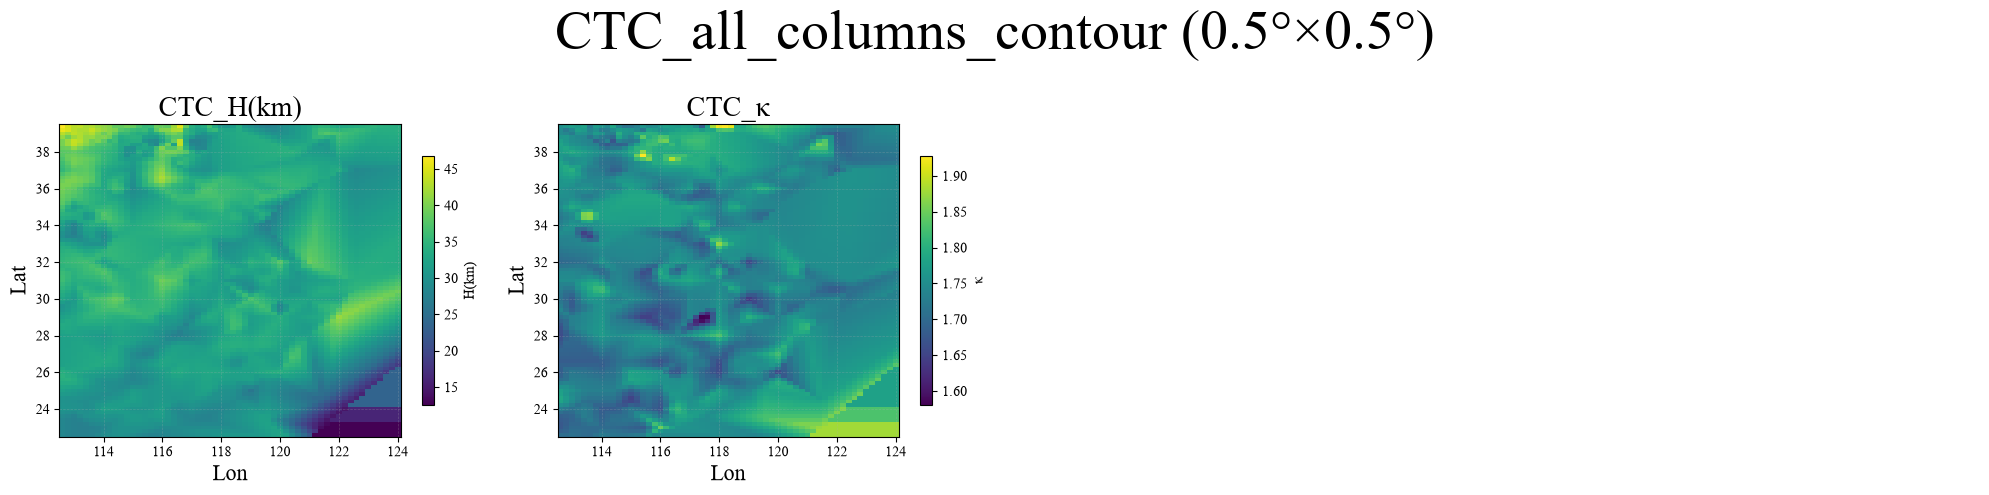


正在生成所有列的热点图矩阵（连续图）...


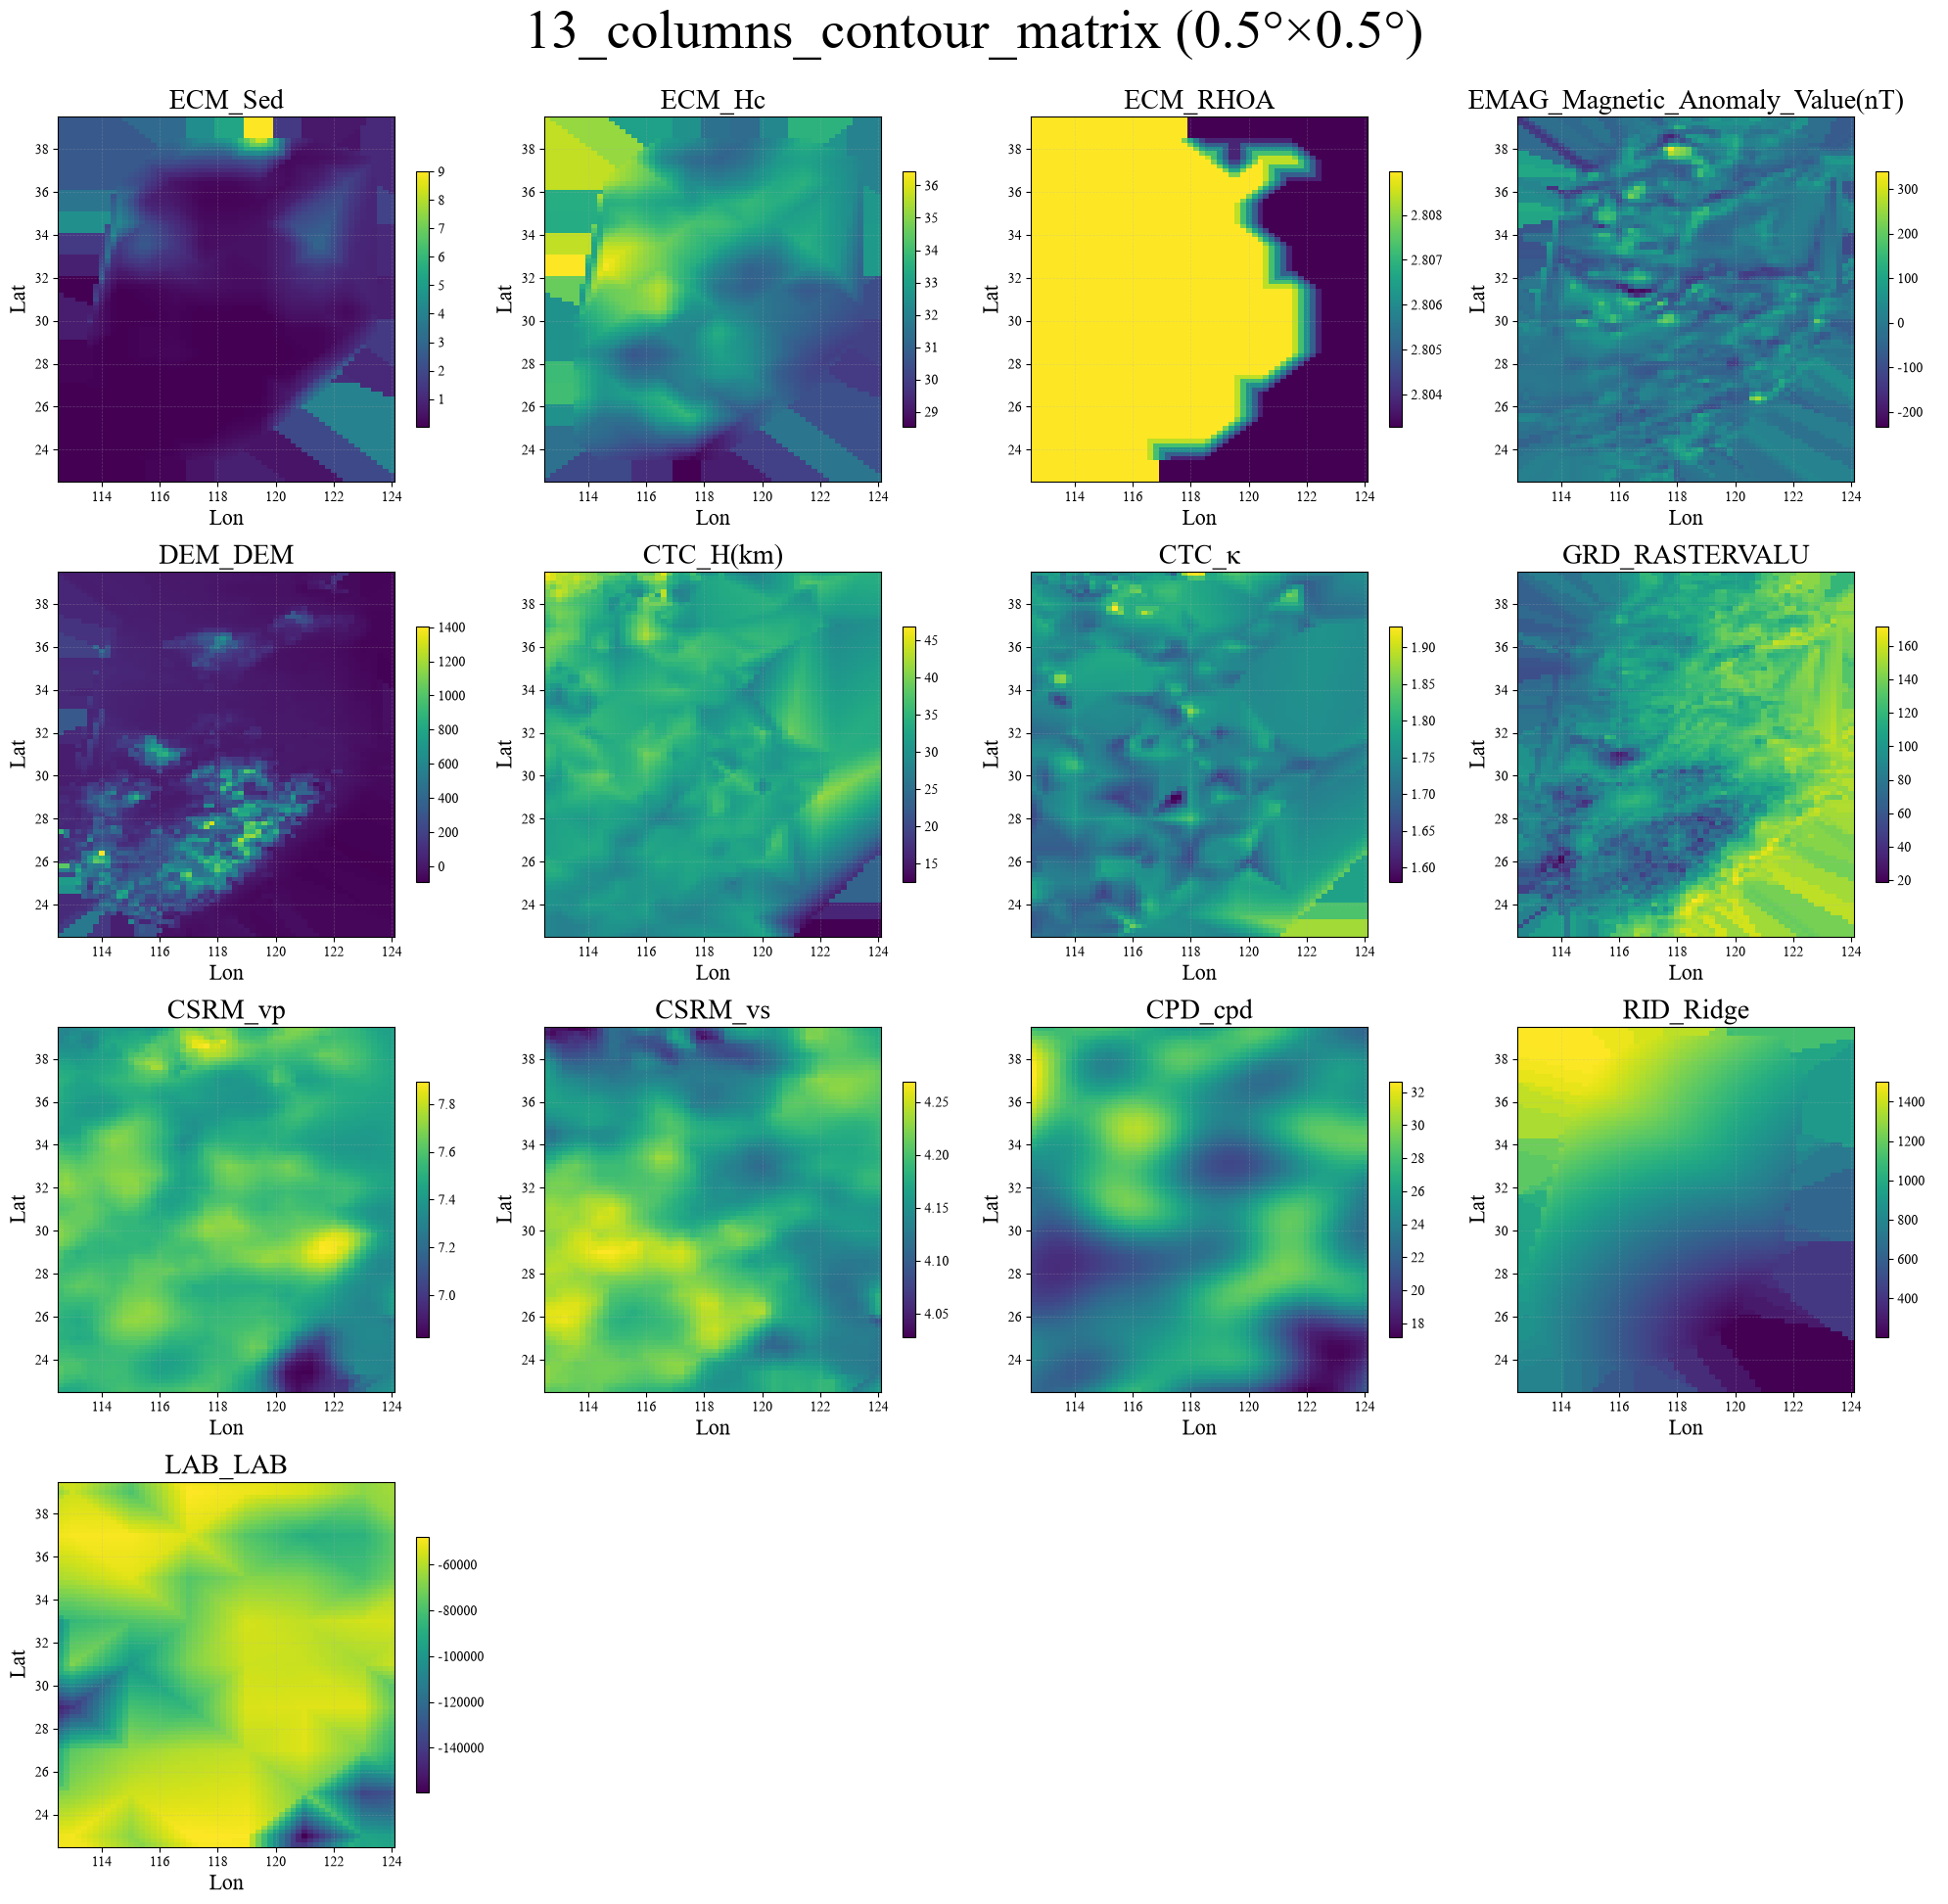


可视化完成，生成的文件:
  ECM_all_columns_contour.png - ECM数据集的所有3个列
  EMAG_all_columns_contour.png - EMAG数据集的所有1个列
  DEM_all_columns_contour.png - DEM数据集的所有1个列
  CTC_all_columns_contour.png - CTC数据集的所有2个列
  top_columns_contour_matrix.png - 前13个数据列的热点图矩阵（连续图，含轮廓）


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from shapely.geometry import LineString, MultiLineString

print("\n开始生成可视化图表...")

# ==================== 加载华东地区轮廓 shapefile ====================
shapefile_path = '../data/eastChinaLine.shp'  # 请根据实际路径修改
try:
    gdf = gpd.read_file(shapefile_path)
    if gdf.crs != 'EPSG:4326':
        gdf = gdf.to_crs('EPSG:4326')
    print("成功加载华东地区轮廓文件")
    print("Shapefile 信息:")
    print(f"  CRS: {gdf.crs}")
    print(f"  几何类型: {gdf.geometry.type.unique()}")
    print(f"  记录数: {len(gdf)}")
    print(f"  总边界范围: {gdf.total_bounds}")

    # 自定义函数：提取所有边界线坐标并绘制
    def plot_shapefile_boundary(ax, gdf, color='black', linewidth=0.5):
        """
        将 GeoDataFrame 中的所有几何体的轮廓绘制到 ax 上。
        对于 Polygon/MultiPolygon，取其边界；对于 LineString，直接使用几何体。
        """
        for geom in gdf.geometry:
            if geom.is_empty:
                continue
            # 获取要绘制的几何体（如果是面，取边界；否则用自身）
            if geom.geom_type in ['Polygon', 'MultiPolygon']:
                geom_to_plot = geom.boundary
            else:
                geom_to_plot = geom

            # 绘制线状几何体
            if geom_to_plot.geom_type == 'LineString':
                x, y = zip(*geom_to_plot.coords)
                ax.plot(x, y, color=color, linewidth=linewidth)
            elif geom_to_plot.geom_type == 'MultiLineString':
                for line in geom_to_plot.geoms:
                    x, y = zip(*line.coords)
                    ax.plot(x, y, color=color, linewidth=linewidth)
            # 忽略其他类型（如 Point）

    print("自定义轮廓绘制函数已定义")

except Exception as e:
    print(f"加载 shapefile 失败: {e}，将不绘制轮廓线")
    gdf = None
    plot_shapefile_boundary = None

# 获取非经纬度的数据列
data_columns = [col for col in merged_df.columns if col not in ['Latitude', 'Longitude']]

# 为每个数据集获取所有列
datasets_to_plot = ['ECM', 'EMAG', 'DEM', 'CTC']

# 按数据集组织列
dataset_columns = {}
for dataset in datasets_to_plot:
    dataset_cols = [col for col in data_columns if col.startswith(f'{dataset}_')]
    if dataset_cols:
        dataset_columns[dataset] = dataset_cols

# ==================== 为每个数据集的所有列生成连续图（带轮廓线）====================
for dataset, cols in dataset_columns.items():
    print(f"正在为数据集 {dataset} 的 {len(cols)} 个列生成连续图...")
    
    n_cols = len(cols)
    n_rows = int(np.ceil(n_cols / 4))
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, n_rows*5))
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    axes_flat = axes.flatten()
    
    for idx, col_name in enumerate(cols):
        ax = axes_flat[idx]
        
        # 提取数据，移除NaN值
        plot_data = merged_df[['Longitude', 'Latitude', col_name]].dropna()
        
        if len(plot_data) > 0:
            # 将数据重塑为二维网格
            pivot = plot_data.pivot_table(index='Latitude', columns='Longitude', values=col_name)
            lons = pivot.columns.values
            lats = pivot.index.values
            lon2d, lat2d = np.meshgrid(lons, lats)
            value_grid = pivot.values
            
            # 绘制 pcolormesh 连续图
            mesh = ax.pcolormesh(lon2d, lat2d, value_grid, cmap='viridis', shading='auto')
            
            # 添加颜色条
            plt.colorbar(mesh, ax=ax, shrink=0.8, label=col_name.split('_', 1)[1] if '_' in col_name else col_name)
            
            ax.set_title(f'{col_name}', fontsize=20)
            ax.set_xlabel('Lon', fontsize=16)
            ax.set_ylabel('Lat', fontsize=16)
            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
        else:
            ax.text(0.5, 0.5, f'{col_name}\n无有效数据', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{col_name} (无数据)', fontsize=16)
            ax.set_xlabel('Lon', fontsize=16)
            ax.set_ylabel('Lat', fontsize=16)
        
        # ===== 绘制华东地区轮廓线（自定义函数，无纵横比问题）=====
        if gdf is not None and plot_shapefile_boundary is not None:
            plot_shapefile_boundary(ax, gdf, color='red', linewidth=1.5)
    
    # 隐藏多余子图
    for idx in range(len(cols), len(axes_flat)):
        axes_flat[idx].axis('off')
    
    plt.suptitle(f'{dataset}_all_columns_contour (0.5°×0.5°)', fontsize=40, y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f'../output/fig/preprocess/{dataset}_all_columns_contour.png', dpi=300, bbox_inches='tight')
    plt.show()

# ==================== 生成所有列的热点图矩阵（连续图，带轮廓线）====================
print("\n正在生成所有列的热点图矩阵（连续图）...")

top_columns = data_columns
n_top_cols = len(top_columns)
n_top_rows = int(np.ceil(n_top_cols / 4))

fig, axes = plt.subplots(n_top_rows, 4, figsize=(20, n_top_rows*5))
if n_top_rows == 1:
    axes = axes.reshape(1, -1)
axes_flat = axes.flatten()

for idx, col_name in enumerate(top_columns):
    ax = axes_flat[idx]
    
    plot_data = merged_df[['Longitude', 'Latitude', col_name]].dropna()
    
    if len(plot_data) > 0:
        # 重塑为二维网格
        pivot = plot_data.pivot_table(index='Latitude', columns='Longitude', values=col_name)
        lons = pivot.columns.values
        lats = pivot.index.values
        lon2d, lat2d = np.meshgrid(lons, lats)
        value_grid = pivot.values
        
        mesh = ax.pcolormesh(lon2d, lat2d, value_grid, cmap='viridis', shading='auto')
        plt.colorbar(mesh, ax=ax, shrink=0.7, label='')
        
        ax.set_title(f'{col_name}', fontsize=20)
        ax.set_xlabel('Lon', fontsize=16)
        ax.set_ylabel('Lat', fontsize=16)
        ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    else:
        ax.text(0.5, 0.5, f'{col_name}\n无有效数据', ha='center', va='center', transform=ax.transAxes, fontsize=9)
        ax.set_title(f'{col_name} (无数据)', fontsize=9)
        ax.set_xlabel('Lon')
        ax.set_ylabel('Lat')
    
    # ===== 绘制华东地区轮廓线（自定义函数）=====
    if gdf is not None and plot_shapefile_boundary is not None:
        plot_shapefile_boundary(ax, gdf, color='red', linewidth=1.5)

# 隐藏多余子图
for idx in range(len(top_columns), len(axes_flat)):
    axes_flat[idx].axis('off')

plt.suptitle(f'{len(top_columns)}_columns_contour_matrix (0.5°×0.5°)', fontsize=40, y=0.97)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('../output/fig/preprocess/top_columns_contour_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# 生成统计信息
print("\n可视化完成，生成的文件:")
for dataset in datasets_to_plot:
    if dataset in dataset_columns and len(dataset_columns[dataset]) > 0:
        print(f"  {dataset}_all_columns_contour.png - {dataset}数据集的所有{len(dataset_columns[dataset])}个列")
print(f"  top_columns_contour_matrix.png - 前{len(top_columns)}个数据列的热点图矩阵（连续图，含轮廓）")

In [14]:
import numpy as np
from scipy.interpolate import griddata

def interpolate_to_points(df, lat_col, lon_col, data_col, target_lats, target_lons):
    """
    使用线性插值（基于三角剖分）将数据插值到指定的经纬度点上。
    对于凸包外的点，使用最近邻插值填充。
    """
    # 提取有效数据点
    mask = df[data_col].notna()
    if mask.sum() < 3:   # 线性插值至少需要3个非共线点
        return np.full(len(target_lats), np.nan)
    
    x = df.loc[mask, lon_col].values   # 经度
    y = df.loc[mask, lat_col].values   # 纬度
    z = df.loc[mask, data_col].values  # 值
    
    # 目标点坐标数组
    target_points = np.column_stack([target_lons, target_lats])
    
    try:
        # 线性插值（基于Delaunay三角剖分）
        z_interp = griddata(
            points=np.column_stack([x, y]),
            values=z,
            xi=target_points,
            method='linear'
        )
        
        # 线性插值在凸包外会产生 NaN，用最近邻填充
        nan_mask = np.isnan(z_interp)
        if nan_mask.any():
            z_nearest = griddata(
                points=np.column_stack([x, y]),
                values=z,
                xi=target_points[nan_mask],
                method='nearest'
            )
            z_interp[nan_mask] = z_nearest
        
        return z_interp
        
    except Exception as e:
        print(f"  插值失败: {e}")
        return np.full(len(target_lats), np.nan)


# ========= 主程序 =========
# 获取 df_SHF 的数据点
shf_lats = df_SHF['Lat'].values
shf_lons = df_SHF['Lon'].values

print(f"SHF数据点数量: {len(shf_lats)}")

# 初始化结果DataFrame，以df_SHF为基础
result_df = df_SHF.copy()

# 定义跳过的列名
skip_columns = ['OBJECTID', 'pointid', 'Numb', 'Type', 'RF type', 
                'Hcc', 'VPN', 'VPA', 'VSA', 'VSN', 'RHON', '△H(km)', '△κ']

# 对每个数据集进行插值
for name, df in datasets.items():
    print(f"\n处理 {name}...")
    
    data_cols = [col for col in df.columns if col not in ['Lat', 'Lon']]
    
    for col_idx, data_col in enumerate(data_cols):
        print(f"  列 {col_idx+1}/{len(data_cols)}: {data_col}", end="")
        if data_col in skip_columns:
            print(" - 跳过")
            continue
        
        # 插值到SHF点（线性插值）
        interpolated_values = interpolate_to_points(
            df, 'Lat', 'Lon', data_col,
            shf_lats, shf_lons
        )
        
        # 添加到结果DataFrame
        result_df[f"{name}_{data_col}"] = interpolated_values
        
        # 计算有效数据比例
        valid_ratio = 1 - np.isnan(interpolated_values).sum() / len(interpolated_values)
        print(f" - 有效数据: {valid_ratio:.1%}")

print(f"\n插值完成，结果DataFrame形状: {result_df.shape}")

SHF数据点数量: 703

处理 ECM...
  列 1/12: OBJECTID - 跳过
  列 2/12: Numb - 跳过
  列 3/12: Hcc - 跳过
  列 4/12: Sed - 有效数据: 100.0%
  列 5/12: Hc - 有效数据: 100.0%
  列 6/12: Type - 跳过
  列 7/12: VPN - 跳过
  列 8/12: VSN - 跳过
  列 9/12: RHON - 跳过
  列 10/12: VPA - 跳过
  列 11/12: VSA - 跳过
  列 12/12: RHOA - 有效数据: 100.0%

处理 EMAG...
  列 1/3: OBJECTID - 跳过
  列 2/3: pointid - 跳过
  列 3/3: Magnetic_Anomaly_Value(nT) - 有效数据: 100.0%

处理 DEM...
  列 1/3: OBJECTID - 跳过
  列 2/3: pointid - 跳过
  列 3/3: DEM - 有效数据: 100.0%

处理 CTC...
  列 1/5: H(km) - 有效数据: 100.0%
  列 2/5: △H(km) - 跳过
  列 3/5: κ - 有效数据: 100.0%
  列 4/5: △κ - 跳过
  列 5/5: RF type - 跳过

处理 GRD...
  列 1/2: pointid - 跳过
  列 2/2: RASTERVALU - 有效数据: 100.0%

处理 CSRM...
  列 1/2: vp - 有效数据: 100.0%
  列 2/2: vs - 有效数据: 100.0%

处理 CPD...
  列 1/1: cpd - 有效数据: 100.0%

处理 RID...
  列 1/1: Ridge - 有效数据: 100.0%

处理 LAB...
  列 1/1: LAB - 有效数据: 100.0%

插值完成，结果DataFrame形状: (703, 17)


In [15]:
# ========== 1. 解析 PB2002_boundaries.dig，构建步长列表 ==========
def parse_title_line(line):
    stripped = line.strip()
    if not stripped:
        return None
    token = stripped.split()[0]
    if len(token) >= 5:
        left = token[0:2]
        btype = token[2]
        right = token[3:5]
        if btype in '-/\\' and left.isalpha() and right.isalpha():
            return left, right, btype
    return None

def parse_coord_line(line):
    line = line.strip()
    if not line:
        return None
    parts = line.split(',')
    if len(parts) != 2:
        return None
    try:
        lon = float(parts[0])
        lat = float(parts[1])
        return lon, lat
    except ValueError:
        return None

def normalize_longitude(lon):
    """将经度转换到 [-180, 180) 范围，确保欧氏距离计算时不会因 350° 和 10° 产生过大误差"""
    if lon >= 180:
        return lon - 360
    elif lon < -180:
        return lon + 360
    return lon

def extract_steps(file_path):
    """返回步长列表，每个步长: {'start': (lon, lat), 'end': (lon, lat), 'type': ...}"""
    steps = []
    with open(file_path, 'r', encoding='utf-8') as f:
        current_segment = None
        current_points = []
        for line in f:
            line = line.rstrip('\n')
            if not line.strip():
                continue
            if line.startswith('*** end of line segment ***'):
                if current_segment is not None and len(current_points) >= 2:
                    for i in range(len(current_points)-1):
                        steps.append({
                            'start': current_points[i],
                            'end': current_points[i+1],
                            'type': current_segment[2]
                        })
                current_segment = None
                current_points = []
                continue
            title_info = parse_title_line(line)
            if title_info is not None and current_segment is None:
                current_segment = title_info
                current_points = []
                continue
            coord = parse_coord_line(line)
            if coord is not None and current_segment is not None:
                current_points.append(coord)
        # 文件末尾处理
        if current_segment is not None and len(current_points) >= 2:
            for i in range(len(current_points)-1):
                steps.append({
                    'start': current_points[i],
                    'end': current_points[i+1],
                    'type': current_segment[2]
                })
    return steps

In [16]:
# ========== 2. 平面欧氏距离工具 ==========
def point_to_segment_distance_euclidean(point, seg_start, seg_end):
    """
    计算点 (lon, lat) 到线段 (起点, 终点) 的欧氏距离（经纬度平面）。
    返回距离值（单位：度）。
    """
    x0, y0 = point[0], point[1]
    x1, y1 = seg_start[0], seg_start[1]
    x2, y2 = seg_end[0], seg_end[1]
    
    # 计算线段向量和点向量
    dx = x2 - x1
    dy = y2 - y1
    
    # 线段长度平方
    seg_len_sq = dx*dx + dy*dy
    if seg_len_sq == 0:
        # 线段退化为点
        return np.hypot(x0 - x1, y0 - y1)
    
    # 投影参数 t = ( (x0-x1)*dx + (y0-y1)*dy ) / seg_len_sq
    t = ((x0 - x1)*dx + (y0 - y1)*dy) / seg_len_sq
    if t <= 0:
        # 最近点为起点
        return np.hypot(x0 - x1, y0 - y1)
    elif t >= 1:
        # 最近点为终点
        return np.hypot(x0 - x2, y0 - y2)
    else:
        # 最近点为垂足
        proj_x = x1 + t * dx
        proj_y = y1 + t * dy
        return np.hypot(x0 - proj_x, y0 - proj_y)
    
def add_distance_to_boundary_euclidean(df, steps, lon_col='longitude', lat_col='latitude', dist_col='dist_to_boundary_deg'):
    """
    为 DataFrame 添加一列，表示每个点到最近板块边界的欧氏距离（单位：度）。
    """
    distances = []
    for idx, row in df.iterrows():
        lon = row[lon_col]
        lat = row[lat_col]
        # 经度归一化到 [-180,180)，避免跨越 360° 问题
        lon_norm = normalize_longitude(lon)
        point = (lon_norm, lat)
        min_dist = float('inf')
        for step in steps:
            # 注意：步长的经纬度也需归一化，但 extract_steps 中存储的可能是 0-360 形式
            start_norm = (normalize_longitude(step['start'][0]), step['start'][1])
            end_norm = (normalize_longitude(step['end'][0]), step['end'][1])
            d = point_to_segment_distance_euclidean(point, start_norm, end_norm)
            if d < min_dist:
                min_dist = d
                if min_dist < 1e-8:
                    break
        distances.append(min_dist)
    df[dist_col] = distances
    return df

In [17]:
# ========== 3. 使用示例 ==========
boundary_file = '../data/pb2002_boundaries.dig'
steps = extract_steps(boundary_file)
print(f'Loaded {len(steps)} boundary steps.')

# 假设 merged_df 和 result_df 已经存在，且包含经度、纬度列（例如 'longitude', 'latitude'）
merged_df = add_distance_to_boundary_euclidean(merged_df, steps, lon_col='Longitude', lat_col='Latitude')
result_df = add_distance_to_boundary_euclidean(result_df, steps, lon_col='Lon', lat_col='Lat')

# 查看结果（距离单位：度）
print(merged_df[['Longitude', 'Latitude', 'dist_to_boundary_deg']].head())
print(result_df[['Lon', 'Lat', 'dist_to_boundary_deg']].head())

Loaded 5819 boundary steps.
   Longitude  Latitude  dist_to_boundary_deg
0      112.6      22.6              0.952715
1      112.8      22.6              1.082805
2      113.0      22.6              1.231774
3      113.2      22.6              1.393580
4      113.4      22.6              1.563942
          Lon        Lat  dist_to_boundary_deg
0  116.133333  23.316667              2.614231
1  116.628333  23.551667              2.351899
2  114.011178  23.582858              2.638842
3  114.012938  23.591441              2.645863
4  117.482069  23.738516              1.914860


In [18]:
import struct
from shapely.geometry import LineString, MultiLineString
from shapely.geometry import Point

def read_shp_lines(shp_path):
    """
    从 .shp 文件读取所有线要素，返回 Shapely LineString/MultiLineString 列表。
    忽略 Z、M 值，仅用 X、Y。
    """
    geoms = []
    with open(shp_path, 'rb') as f:
        # 跳过文件头（100 字节）
        f.seek(100)
        while True:
            # 读取记录头（8 字节：记录号（大端）、内容长度（大端，单位为 2 字节字））
            head = f.read(8)
            if len(head) < 8:
                break
            rec_num, content_len_words = struct.unpack('>ii', head)
            content_len = content_len_words * 2   # 字节数
            content = f.read(content_len)
            if len(content) < content_len:
                break

            # 解析内容
            shape_type = struct.unpack('<i', content[:4])[0]
            # 仅处理 Polyline (3), PolylineZ (13), PolylineM (23)
            if shape_type not in (3, 13, 23):
                continue

            # 跳过 bbox (4 个 double)
            offset = 4 + 4*8
            # 读取 numParts, numPoints
            numParts, numPoints = struct.unpack('<ii', content[offset:offset+8])
            offset += 8
            # 读取 parts 数组
            parts = struct.unpack('<{}i'.format(numParts), content[offset:offset+4*numParts])
            offset += 4*numParts

            # 读取所有点 (每个点 X,Y 各 8 字节，共 16 字节)
            points = []
            for i in range(numPoints):
                x, y = struct.unpack('<dd', content[offset + i*16 : offset + i*16 + 16])
                points.append((x, y))

            # 构建几何
            lines = []
            for i in range(numParts):
                start = parts[i]
                end = parts[i+1] if i+1 < numParts else numPoints
                seg = points[start:end]
                if len(seg) >= 2:
                    lines.append(LineString(seg))
            if lines:
                geoms.append(MultiLineString(lines) if len(lines) > 1 else lines[0])
    return geoms

# 使用
fault_geoms = read_shp_lines('../data/CAFD400_V2023.shp')
print(f'Loaded {len(fault_geoms)} fault features.')

Loaded 8995 fault features.


In [19]:
def add_fault_distances(df, fault_geoms, lon_col, lat_col, 
                        dtf1_col='DTF1', dtfa_col='DTFA'):
    """
    为 DataFrame 添加 DTF1 和 DTFA 两列。

    参数：
        df: pandas DataFrame，需包含经纬度列
        fault_geoms: list of shapely geometries (LineString 或 MultiLineString)
        lon_col: 经度列名
        lat_col: 纬度列名
        dtf1_col: 最近距离列名
        dtfa_col: 前5平均距离列名
    返回：
        添加两列后的 DataFrame（原地修改）
    """
    dtf1_list = []
    dtfa_list = []
    
    for idx, row in df.iterrows():
        point = Point(row[lon_col], row[lat_col])
        # 计算到每条断裂的距离（平面欧氏，单位：度）
        dists = [point.distance(geom) for geom in fault_geoms]
        # 排序
        dists.sort()
        # 最近距离
        min_dist = dists[0] if dists else np.nan
        # 前5平均（若不足5个则全取）
        top5 = dists[:5]
        avg_dist = np.mean(top5) if top5 else np.nan
        
        dtf1_list.append(min_dist)
        dtfa_list.append(avg_dist)
    
    df[dtf1_col] = dtf1_list
    df[dtfa_col] = dtfa_list
    return df

In [20]:
# 计算 merged_df
merged_df = add_fault_distances(merged_df, fault_geoms, 
                                lon_col='Longitude', lat_col='Latitude',
                                dtf1_col='DTF1', dtfa_col='DTFA')

# 计算 result_df
result_df = add_fault_distances(result_df, fault_geoms,
                                lon_col='Lon', lat_col='Lat',
                                dtf1_col='DTF1', dtfa_col='DTFA')

# 查看结果
print(merged_df[['Longitude', 'Latitude', 'DTF1', 'DTFA']].head())
print(result_df[['Lon', 'Lat', 'DTF1', 'DTFA']].head())

   Longitude  Latitude      DTF1      DTFA
0      112.6      22.6  0.056634  0.098407
1      112.8      22.6  0.020955  0.065185
2      113.0      22.6  0.088283  0.105716
3      113.2      22.6  0.029173  0.101625
4      113.4      22.6  0.076538  0.152989
          Lon        Lat      DTF1      DTFA
0  116.133333  23.316667  0.012207  0.046851
1  116.628333  23.551667  0.104515  0.125121
2  114.011178  23.582858  0.312577  0.339574
3  114.012938  23.591441  0.310034  0.344713
4  117.482069  23.738516  0.015109  0.108242


In [21]:
from GlobalTe.globalte import TeModel as TM
model = TM()
#te = model.get_te_point(22.6, 112.6)
#print(f"计算得到的 Te 值为: {te:.4f}")
def add_te_column(df, lon_col, lat_col):
    """
    为 DataFrame 添加 Te 列（手动逐行计算，更稳健）。
    参数:
        df: pandas DataFrame，需包含经度和纬度列
        lon_col: 经度列名（例如 'lon' 或 'longitude'）
        lat_col: 纬度列名（例如 'lat' 或 'latitude'）
    返回:
        添加了新列 'te' 的 DataFrame（原地修改）
    """
    te_values = []
    # 方法一：使用 iterrows（直观但稍慢）
    for idx, row in df.iterrows():
        try:
            te_val = model.get_te_point(row[lat_col], row[lon_col])
            #print(f"第 {idx} 行计算成功: Te = {te_val:.4f}")
        except Exception as e:
            print(f"第 {idx} 行计算失败: {e}")
            te_val = None   # 或 np.nan
        te_values.append(te_val)
    
    df['te'] = te_values
    return df

# 自动检测列名（根据常见命名）
def detect_coord_columns(df):
    """尝试从 DataFrame 中识别经度列和纬度列"""
    possible_lon = ['Lon', 'Longitude', 'lng', 'long']
    possible_lat = ['Lat', 'Latitude']
    
    lon_col = next((col for col in possible_lon if col in df.columns), None)
    lat_col = next((col for col in possible_lat if col in df.columns), None)
    
    if lon_col is None or lat_col is None:
        raise ValueError("DataFrame 中缺少经度或纬度列，请手动指定列名")
    return lon_col, lat_col

# 处理 merged_df
if 'merged_df' in locals():
    lon_col, lat_col = detect_coord_columns(merged_df)
    add_te_column(merged_df, lon_col, lat_col)
    print(f"merged_df 已添加 Te 列，使用经度列: {lon_col}, 纬度列: {lat_col}")

# 处理 result_df
if 'result_df' in locals():
    lon_col, lat_col = detect_coord_columns(result_df)
    add_te_column(result_df, lon_col, lat_col)
    print(f"result_df 已添加 Te 列，使用经度列: {lon_col}, 纬度列: {lat_col}")


# 查看结果（距离单位：度）
print(merged_df[['Longitude', 'Latitude', 'te']].head())
print(result_df[['Lon', 'Lat', 'te']].head())

merged_df 已添加 Te 列，使用经度列: Longitude, 纬度列: Latitude
result_df 已添加 Te 列，使用经度列: Lon, 纬度列: Lat
   Longitude  Latitude         te
0      112.6      22.6  16.567331
1      112.8      22.6  16.567331
2      113.0      22.6  18.087290
3      113.2      22.6  18.087290
4      113.4      22.6  18.087290
          Lon        Lat         te
0  116.133333  23.316667  19.179287
1  116.628333  23.551667  19.179287
2  114.011178  23.582858  15.751429
3  114.012938  23.591441  15.751429
4  117.482069  23.738516  20.680096


In [22]:
# 保存结果
output_path = '../output/merged_all_datasets.xlsx'
merged_df.to_excel(output_path, index=False)
print(f"已保存到: {output_path}")
output_path = '../output/interpolated_to_SHF.xlsx'
result_df.to_excel(output_path, index=False)
print(f"已保存到: {output_path}")

已保存到: ../output/merged_all_datasets.xlsx
已保存到: ../output/interpolated_to_SHF.xlsx


✅ 重采样结果已保存。
重采样后网格点数量: 400
   Latitude  Longitude  ECM_Sed    ECM_Hc  ECM_RHOA  \
0      23.4      116.2    0.100  29.55440  2.808968   
1      23.6      114.0    0.010  30.27380  2.808968   
2      23.6      116.6    0.131  29.59588  2.808398   
3      23.8      114.2    0.010  30.62438  2.808968   
4      23.8      117.2    0.353  29.26624  2.804981   

   EMAG_Magnetic_Anomaly_Value(nT)  DEM_DEM  CTC_H(km)  CTC_κ  GRD_RASTERVALU  \
0                        48.832220     13.5      30.48  1.740      106.400760   
1                         7.226889    515.0      30.42  1.688       69.410561   
2                        11.980681     16.0      28.64  1.788      114.402540   
3                        -5.053000    367.0      31.06  1.692       77.481104   
4                       -11.941409    101.5      28.55  1.773       96.497925   

    CSRM_vp   CSRM_vs  CPD_cpd   RID_Ridge    LAB_LAB  dist_to_boundary_deg  \
0  7.444176  4.212524  25.8616  557.208408 -53277.926              2.608931 

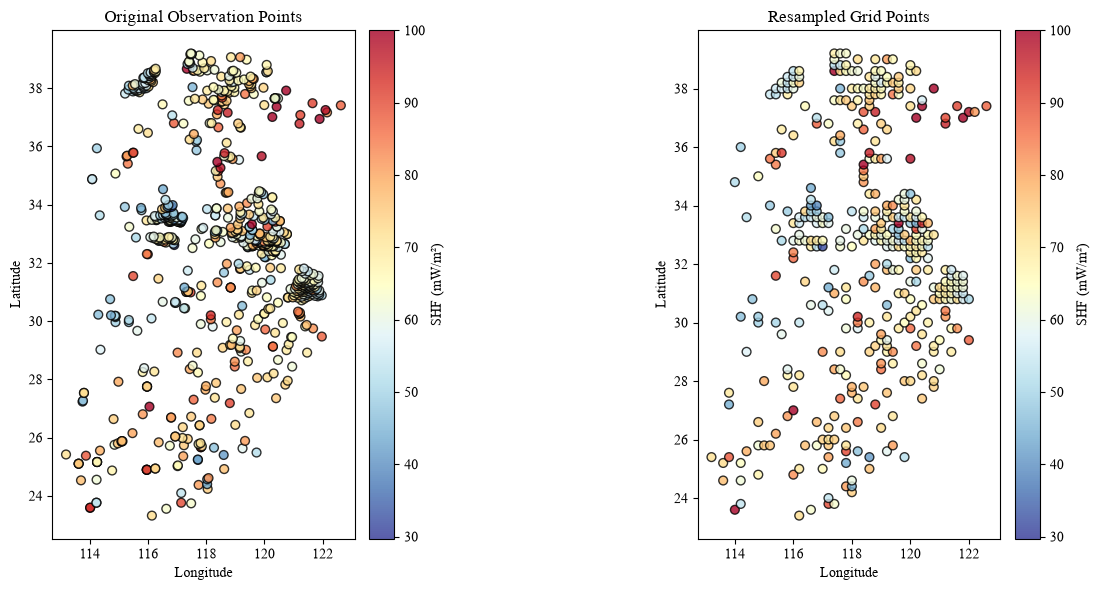

✅ 重采样结果已保存，空间分布图已生成。


In [23]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree
import matplotlib.pyplot as plt

# ------------------------------
# 1. 读取数据
# ------------------------------
df_SHF = pd.read_excel('../output/interpolated_to_SHF.xlsx')   # 地表热流观测点
df_GEO = pd.read_excel('../output/merged_all_datasets.xlsx')   # 0.2° 规则网格数据

# ------------------------------
# 2. 提取坐标与数值
# ------------------------------
obs_lons = df_SHF['Lon'].values
obs_lats = df_SHF['Lat'].values
obs_values = df_SHF['SHF__mW_m2_'].values  # 热流值列名（请确认）

# 网格点（唯一经纬度）
grid = df_GEO[['Longitude', 'Latitude']].drop_duplicates().values
grid_lons = grid[:, 0]
grid_lats = grid[:, 1]

# ------------------------------
# 3. 构建 BallTree 并查询最近网格点
# ------------------------------
obs_rad = np.radians(np.column_stack((obs_lats, obs_lons)))
grid_rad = np.radians(np.column_stack((grid_lats, grid_lons)))

tree = BallTree(grid_rad, metric='haversine')
distances_rad, indices = tree.query(obs_rad, k=1)
distances_km = distances_rad.flatten() * 6371.0
indices = indices.flatten()

# ------------------------------
# 4. 反距离加权平均
# ------------------------------
obs_df = pd.DataFrame({
    'grid_idx': indices,
    'dist_km': distances_km,
    'value': obs_values
})

def weighted_mean(group, p=1, eps=1e-6):
    weights = 1.0 / (group['dist_km']**p + eps)
    return np.average(group['value'], weights=weights)

resampled = obs_df.groupby('grid_idx').apply(
    lambda g: weighted_mean(g, p=1)
).reset_index(name='SHF_resampled')

# ------------------------------
# 5. 映射到网格并筛选有值点
# ------------------------------
result_df = pd.DataFrame({
    'Longitude': grid_lons,
    'Latitude': grid_lats,
    'SHF_resampled': np.nan
})
result_df.loc[resampled['grid_idx'], 'SHF_resampled'] = resampled['SHF_resampled'].values

# 仅保留有重采样值的网格点
result_df = result_df.dropna(subset=['SHF_resampled'])

# 内连接保留 df_GEO 的全部属性
df_GEO_filtered = df_GEO.merge(result_df, on=['Longitude', 'Latitude'], how='inner')

# 保存结果（只含有点的完整属性）
df_GEO_filtered.to_excel('../output/model/mesh/SHF_resampled_to_grid.xlsx', index=False)

print("✅ 重采样结果已保存。")
print(f"重采样后网格点数量: {len(df_GEO_filtered)}")
print(df_GEO_filtered.head())

# ------------------------------
# 6. 绘制空间分布对比图
# ------------------------------
# 统一色阶范围：低值=原始观测最小值，高值=100
vmin = obs_values.min()
vmax = 100.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# 左图：原始观测点
sc1 = ax1.scatter(obs_lons, obs_lats, c=obs_values, cmap='RdYlBu_r',
                  vmin=vmin, vmax=vmax, edgecolors='k', s=40, alpha=0.8)
ax1.set_title('Original Observation Points', fontsize=12)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax1.set_aspect('equal')

cbar1 = plt.colorbar(sc1, ax=ax1, orientation='vertical', pad=0.02)
cbar1.set_label('SHF (mW/m²)')

# 右图：重采样网格点
resampled_lons = df_GEO_filtered['Longitude'].values
resampled_lats = df_GEO_filtered['Latitude'].values
resampled_vals = df_GEO_filtered['SHF_resampled'].values

sc2 = ax2.scatter(resampled_lons, resampled_lats, c=resampled_vals, cmap='RdYlBu_r',
                  vmin=vmin, vmax=vmax, edgecolors='k', s=40, alpha=0.8)
ax2.set_title('Resampled Grid Points', fontsize=12)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
ax2.set_aspect('equal')

cbar2 = plt.colorbar(sc2, ax=ax2, orientation='vertical', pad=0.02)
cbar2.set_label('SHF (mW/m²)')

plt.tight_layout()
plt.savefig('../output/model/mesh/SHF_spatial_distribution.png', dpi=3000, bbox_inches='tight')
plt.show()

print("✅ 重采样结果已保存，空间分布图已生成。")

In [30]:
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy import stats
df_SHF_processed = pd.read_excel('../output/interpolated_to_SHF.xlsx') #地表热流数据
TARGET_COL = 'SHF__mW_m2_'
GEO_COLS = ['ECM_Sed', 'ECM_RHOA', 'EMAG_Magnetic_Anomaly_Value(nT)', 'RID_Ridge', 'LAB_LAB',
            'DEM_DEM', 'CTC_H(km)', 'GRD_RASTERVALU', 'CSRM_vp', 'CSRM_vs', 'CPD_cpd', 'DTFA']


In [31]:
# 定义原列名与新列名的映射
rename_dict = {
    TARGET_COL: 'SHF'
}
rename_dict.update(dict(zip(GEO_COLS, ['SED', 'RHO', 'MAG', 'DTR', 'LAB', 'DEM', 'MOHO', 'GRAV', 'VP', 'VS', 'CPD', 'DTF'])))

# 执行列名重命名
df_SHF_processed.rename(columns=rename_dict, inplace=True)
TARGET_COL = 'SHF'
GEO_COLS = ['SED', 'RHO', 'MAG', 'DTR', 'LAB', 'DEM', 'MOHO', 'GRAV', 'VP', 'VS', 'CPD', 'DTF']

In [32]:
# 检查列是否存在
required_cols = [TARGET_COL] + GEO_COLS
missing = [col for col in required_cols if col not in df_SHF_processed.columns]
if missing:
    raise KeyError(f"文件中缺少以下列: {missing}")

In [33]:
# 删除缺失值
data = df_SHF_processed[required_cols].dropna()

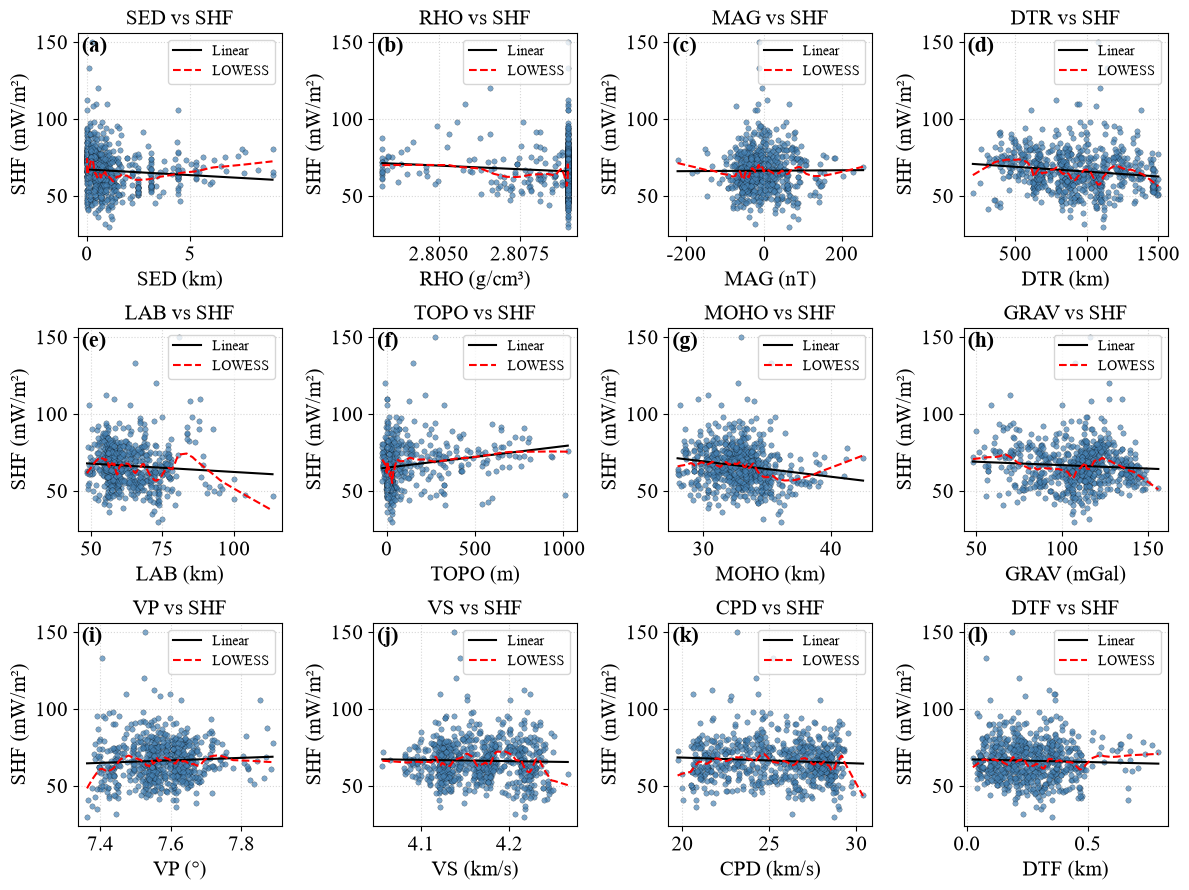

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
plt.rcParams['font.weight'] = 'normal'

# Assume data exists, GEO_COLS is list of feature column names, TARGET_COL is target column name
X_UNITS = ['km', 'g/cm³', 'nT', 'km', 'km', 'm', 'km', 'mGal', '°', 'km/s', 'km/s', 'km', 'km', '°', '°']

n_features = len(GEO_COLS)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3 * n_rows))
axes = axes.flatten()

y_vals = data[TARGET_COL]

for i, feat in enumerate(GEO_COLS):
    ax = axes[i]
    
    # ---------- X-axis value processing: 5th subplot (index 4) divided by 1000 ----------
    if i == 4:
        x = data[feat] / 1000 * -1     # e.g., meters -> kilometers
    else:
        x = data[feat]
    y = data[TARGET_COL]

    # Scatter plot
    ax.scatter(x, y, c='steelblue', s=15, alpha=0.7, edgecolor='k', linewidth=0.2)

    # Linear regression (black solid line)
    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept
    ax.plot(x_line, y_line, 'k-', linewidth=1.5, label='Linear')

    # LOWESS smooth (red dashed line)
    lowess_result = lowess(y, x, frac=0.1, it=3, return_sorted=True)
    ax.plot(lowess_result[:, 0], lowess_result[:, 1],
            'r--', linewidth=1.5, label='LOWESS')

    # ---------- Subplot label (upper-left) ----------
    label = f'({chr(97 + i)})'   # (a), (b), ...
    ax.text(0.02, 0.98, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left')

    # ---------- Axis labels with units (MODIFIED: replace 'DEM' with 'TOPO') ----------
    display_name = 'TOPO' if feat == 'DEM' else feat   # 修改处：若特征名为DEM则显示为TOPO
    ax.set_xlabel(f'{display_name} ({X_UNITS[i]})', fontsize=15)
    ax.set_ylabel('SHF (mW/m²)', fontsize=15)
    ax.set_title(f'{display_name} vs SHF', fontsize=15)   # 标题也同步修改

    ax.tick_params(axis='both', labelsize=15)
    ax.legend(fontsize=10, loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)

# Hide extra subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.tight_layout(rect=[0, 0, 1, 1])
plt.savefig('../output/fig/preprocess/SHF_vs_GEO_features.png', dpi=2000, bbox_inches='tight')
plt.show()

Original CRS: EPSG:4326
Mask polygon type: <class 'shapely.geometry.multipolygon.MultiPolygon'>
Mask geom_type: MultiPolygon
Mask bounds (lon_min, lat_min, lon_max, lat_max): (113.5734020000001, 23.573200000000043, 122.83345400000007, 38.400033000000064)
After masking, valid grid cells: 30247 (total 77740)


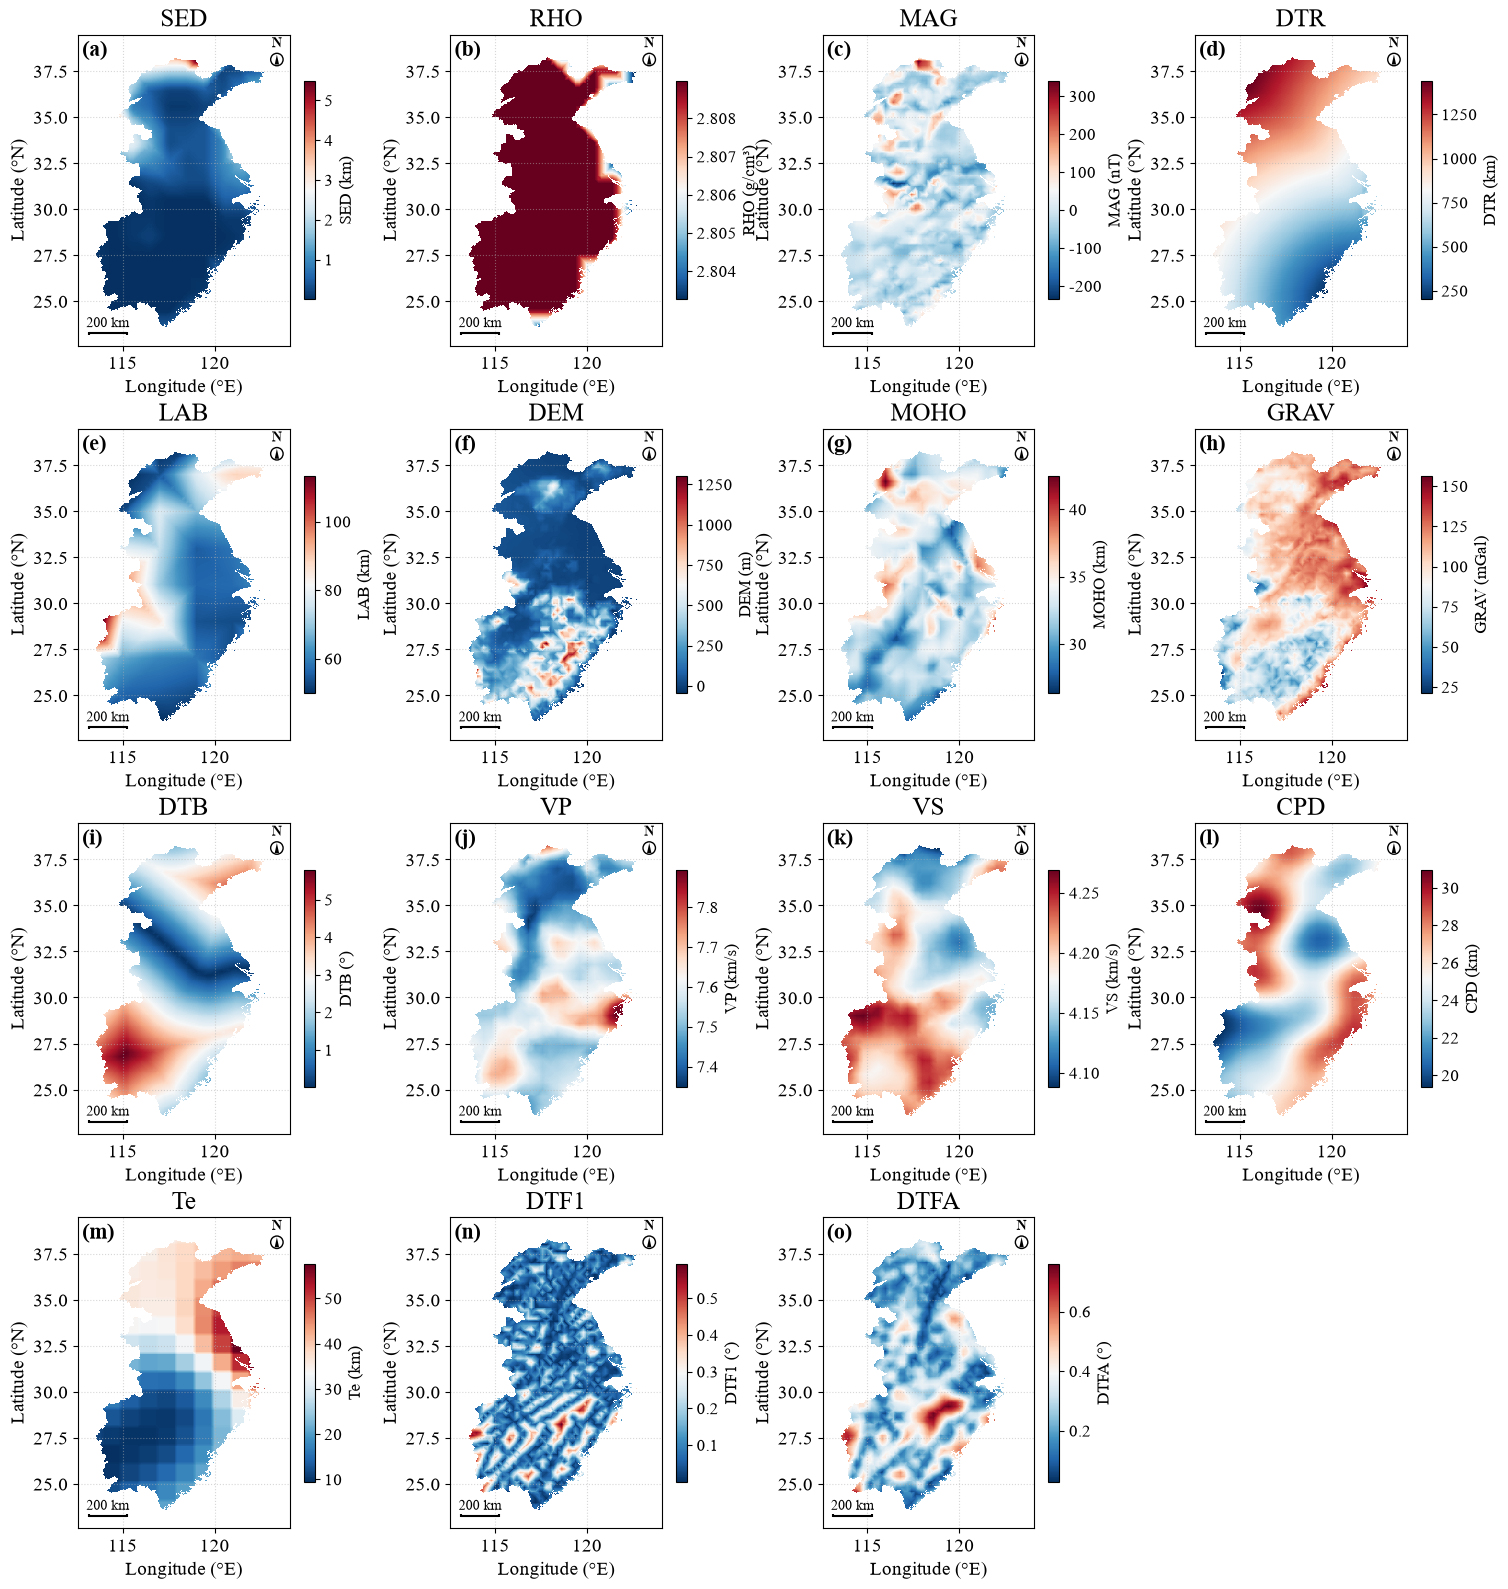

Plotting completed, saved to ../output/fig/preprocess/GEO_COLS_masked_smoothed.png


In [35]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, Polygon, MultiPolygon, LineString, MultiLineString
from shapely.ops import unary_union, polygonize
import warnings
from scipy.interpolate import griddata
from matplotlib.ticker import ScalarFormatter
import pyproj
pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')
plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# ==================== Scale bar and north arrow ====================
def add_scale_bar_line(ax, segment_km=200, line_color='black', fontsize=10):
    """Draw a line scale bar at lower-left corner."""
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    width = xlim[1] - xlim[0]
    height = ylim[1] - ylim[0]
    lat_center = np.mean(ylim)
    km_per_deg_lon = 111.32 * np.cos(np.radians(lat_center))
    seg_deg = segment_km / km_per_deg_lon
    
    x_start = xlim[0] + 0.05 * width
    y_base = ylim[0] + 0.04 * height
    line_height = 0.01 * height
    line_width = seg_deg
    
    ax.hlines(y=y_base, xmin=x_start, xmax=x_start+line_width, 
              colors=line_color, linewidth=1.5, clip_on=False)
    ax.vlines(x=x_start, ymin=y_base-line_height/2, ymax=y_base+line_height/2,
              colors=line_color, linewidth=1.5, clip_on=False)
    ax.vlines(x=x_start+line_width, ymin=y_base-line_height/2, ymax=y_base+line_height/2,
              colors=line_color, linewidth=1.5, clip_on=False)
    ax.text(x_start + line_width/2, y_base + line_height/2 + 0.005*height,
            f'{segment_km} km', ha='center', va='bottom',
            fontsize=fontsize, color=line_color, clip_on=False)

def add_north_arrow(ax, size_ratio=0.02, fontsize=10):
    """Draw a north arrow at upper-right corner."""
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    width = xlim[1] - xlim[0]
    height = ylim[1] - ylim[0]
    margin = 0.06
    x0 = xlim[1] - margin * width
    y0 = ylim[1] - margin * height - 0.02 * height
    radius = size_ratio * height
    arrow_length = 0.8 * radius
    
    circle = mpatches.Circle((x0, y0), radius, facecolor='white', edgecolor='black',
                             linewidth=1.0, zorder=10, clip_on=False)
    ax.add_patch(circle)
    arrow_top = y0 + arrow_length
    arrow_bottom = y0 - arrow_length
    triangle = mpatches.Polygon(
        [(x0, arrow_top), (x0 - 0.35 * radius, arrow_bottom), (x0 + 0.35 * radius, arrow_bottom)],
        facecolor='black', edgecolor='none', zorder=11, clip_on=False
    )
    ax.add_patch(triangle)
    ax.text(x0, y0 + radius + 0.01 * height, 'N',
            ha='center', va='bottom', fontsize=fontsize, fontweight='bold',
            color='black', clip_on=False)

# ==================== Robust mask polygon builder (NO CRS TRANSFORMATION) ====================
def get_mask_polygon(shapefile_path):
    """
    Load shapefile and convert to a polygon mask.
    - Does NOT perform any CRS transformation; assumes original coordinates are lon/lat.
    - Tries polygonize, then forced closure, finally convex_hull fallback.
    """
    if not shapefile_path:
        return None, None
    try:
        gdf = gpd.read_file(shapefile_path)
        print("Original CRS:", gdf.crs)
        # Do NOT reproject – use coordinates as-is.
        # Optionally set crs to 4326 for consistency (if needed)
        if gdf.crs is None:
            gdf.crs = 'EPSG:4326'
        else:
            # keep original, but assume it's already lat/lon
            pass

        union_geom = unary_union(gdf.geometry)
        mask_polygon = None

        if union_geom.geom_type in ['Polygon', 'MultiPolygon']:
            mask_polygon = union_geom
        elif union_geom.geom_type in ['LineString', 'MultiLineString']:
            # 1) Try polygonize
            polygons = list(polygonize(union_geom))
            if polygons:
                mask_polygon = unary_union(polygons)
            else:
                # 2) Force close each line
                def force_close(line):
                    coords = list(line.coords)
                    if len(coords) > 1 and coords[0] != coords[-1]:
                        coords.append(coords[0])
                    return LineString(coords)

                if union_geom.geom_type == 'LineString':
                    closed = force_close(union_geom)
                    if closed.is_ring:
                        mask_polygon = Polygon(closed)
                else:  # MultiLineString
                    closed_lines = [force_close(line) for line in union_geom.geoms]
                    polygons2 = list(polygonize(closed_lines))
                    if polygons2:
                        mask_polygon = unary_union(polygons2)

        # Fallback: convex hull (guarantees a polygon)
        if mask_polygon is None:
            print("Using convex hull as mask polygon (fallback).")
            mask_polygon = union_geom.convex_hull

        # Fix invalid geometries
        if mask_polygon is not None and not mask_polygon.is_valid:
            mask_polygon = mask_polygon.buffer(0)
            if mask_polygon is not None and not mask_polygon.is_valid:
                # If still invalid, use convex hull of the original union
                mask_polygon = union_geom.convex_hull.buffer(0)

        print("Mask polygon type:", type(mask_polygon))
        if mask_polygon is not None:
            print("Mask geom_type:", mask_polygon.geom_type)
            print("Mask bounds (lon_min, lat_min, lon_max, lat_max):", mask_polygon.bounds)
        else:
            print("Mask polygon could not be constructed.")

        return mask_polygon, gdf

    except Exception as e:
        print(f"Failed to load contour file: {e}")
        return None, None

# ==================== Data loading and preprocessing ====================
df_GEO = pd.read_excel('../output/merged_all_datasets.xlsx')
shapefile_path = '../data/eastChinaLine.shp'

mask_polygon, gdf_outline = get_mask_polygon(shapefile_path)

INTERP_FACTOR = 4
INTERP_METHOD = 'linear'

GEO_COLS = ['ECM_Sed', 'ECM_RHOA', 'EMAG_Magnetic_Anomaly_Value(nT)', 'RID_Ridge', 'LAB_LAB',
            'DEM_DEM', 'CTC_H(km)', 'GRD_RASTERVALU', 'dist_to_boundary_deg', 'CSRM_vp', 'CSRM_vs', 'CPD_cpd', 'te', 'DTF1', 'DTFA']
geo_rename_dict = dict(zip(GEO_COLS, ['SED', 'RHO', 'MAG', 'DTR', 'LAB', 'DEM', 'MOHO', 'GRAV', 'DTB', 'VP', 'VS', 'CPD', 'Te', 'DTF1', 'DTFA']))
df_GEO.rename(columns=geo_rename_dict, inplace=True)
GEO_COLS = ['SED', 'RHO', 'MAG', 'DTR', 'LAB', 'DEM', 'MOHO', 'GRAV', 'DTB', 'VP', 'VS', 'CPD', 'Te', 'DTF1', 'DTFA']

UNITS = ['km', 'g/cm³', 'nT', 'km', 'km', 'm', 'km', 'mGal', '°', 'km/s', 'km/s', 'km', 'km', '°', '°']

n_cols = len(GEO_COLS)
n_rows = int(np.ceil(n_cols / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(15, n_rows * 4))
if n_rows == 1:
    axes = axes.reshape(1, -1)
axes_flat = axes.flatten()

# Shapely version handling for point-in-polygon
import shapely
shapely_version = tuple(map(int, shapely.__version__.split('.')[:2]))
if shapely_version >= (2, 0):
    from shapely import contains_xy
    def points_in_polygon(polygon, xs, ys):
        return contains_xy(polygon, xs, ys)
else:
    from shapely.vectorized import contains as vec_contains
    def points_in_polygon(polygon, xs, ys):
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=DeprecationWarning)
            return vec_contains(polygon, xs, ys)

# ==================== Loop over each subplot ====================
for idx, col_name in enumerate(GEO_COLS):
    ax = axes_flat[idx]
    
    plot_data = df_GEO[['Longitude', 'Latitude', col_name]].dropna()
    if len(plot_data) == 0:
        ax.text(0.5, 0.5, f'{col_name}\nNo valid data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(col_name, fontsize=15)
        ax.set_xlabel('Longitude (°E)', fontsize=18)
        ax.set_ylabel('Latitude (°N)', fontsize=18)
        ax.tick_params(axis='both', labelsize=14)
        continue
    
    lons_orig = np.sort(plot_data['Longitude'].unique())
    lats_orig = np.sort(plot_data['Latitude'].unique())
    step_lon = np.diff(lons_orig).min() if len(lons_orig) > 1 else 0.5
    step_lat = np.diff(lats_orig).min() if len(lats_orig) > 1 else 0.5
    
    lon_min, lon_max = lons_orig.min(), lons_orig.max()
    lat_min, lat_max = lats_orig.min(), lats_orig.max()
    new_step_lon = step_lon / INTERP_FACTOR
    new_step_lat = step_lat / INTERP_FACTOR
    lons_new = np.arange(lon_min, lon_max + new_step_lon, new_step_lon)
    lats_new = np.arange(lat_min, lat_max + new_step_lat, new_step_lat)
    lon2d_new, lat2d_new = np.meshgrid(lons_new, lats_new)
    
    points = plot_data[['Longitude', 'Latitude']].values
    values = plot_data[col_name].values
    value_grid_new = griddata(points, values, (lon2d_new, lat2d_new), method=INTERP_METHOD)
    
    # Apply mask if available
    if mask_polygon is not None:
        in_mask = points_in_polygon(mask_polygon, lon2d_new.ravel(), lat2d_new.ravel())
        in_mask = in_mask.reshape(lon2d_new.shape)
        value_grid_new[~in_mask] = np.nan
        if idx == 0:
            valid_after = np.sum(~np.isnan(value_grid_new))
            print(f"After masking, valid grid cells: {valid_after} (total {value_grid_new.size})")
    
    # Special handling for LAB (index 4)
    if idx == 4:
        value_grid_new = -value_grid_new / 1000
    
    mesh = ax.pcolormesh(lon2d_new, lat2d_new, value_grid_new, cmap='RdBu_r', shading='auto')
    cbar = plt.colorbar(mesh, ax=ax, shrink=0.7)
    
    cbar.ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
    cbar.ax.yaxis.get_major_formatter().set_scientific(False)
    cbar.ax.yaxis.offsetText.set_visible(False)
    cbar.ax.tick_params(labelsize=12)
    
    unit = UNITS[idx]
    cbar.set_label(f'{col_name} ({unit})', fontsize=12)
    
    ax.set_title(col_name, fontsize=18)
    ax.set_xlabel('Longitude (°E)', fontsize=14)
    ax.set_ylabel('Latitude (°N)', fontsize=14)
    ax.tick_params(axis='both', labelsize=14)
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.5)
    
    label = f'({chr(97 + idx)})'
    ax.text(0.02, 0.98, label, transform=ax.transAxes, fontsize=16, fontweight='bold', va='top', ha='left')
    
    # Draw contour lines (from original shapefile, if available)
    if gdf_outline is not None:
        for geom in gdf_outline.geometry:
            if geom.is_empty:
                continue
            boundary = geom.boundary
            if boundary.geom_type == 'LineString':
                xb, yb = zip(*boundary.coords)
                ax.plot(xb, yb, color='black', linewidth=1.0)
            elif boundary.geom_type == 'MultiLineString':
                for line in boundary.geoms:
                    xb, yb = zip(*line.coords)
                    ax.plot(xb, yb, color='black', linewidth=1.0)
    
    add_scale_bar_line(ax, segment_km=200, line_color='black', fontsize=10)
    add_north_arrow(ax, size_ratio=0.02, fontsize=10)

# Hide extra subplots
for idx in range(len(GEO_COLS), len(axes_flat)):
    axes_flat[idx].axis('off')

plt.tight_layout(rect=[0, 0, 1, 1], h_pad=0.5)
plt.savefig('../output/fig/preprocess/GEO_COLS_masked_smoothed.png', dpi=2000, bbox_inches='tight')
plt.show()

print("Plotting completed, saved to ../output/fig/preprocess/GEO_COLS_masked_smoothed.png")